In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori,fpgrowth,association_rules

In [3]:
df= pd.read_excel(r"C:\Users\Israel Shitttu\OneDrive - elparahconsult.com\MegaChicken\Practice Claude Analysis Dataset.xlsx",sheet_name='cleaned data')
df.head()

,Line_ID,Invoice_ID,Basket_ID,Order_DateTime,Order_Date,Order_Hour,Weekday,Month,Year,Customer_ID,...,Discount_Percent,Discount_Percent_clean,Gross_Amount_NGN,VAT_Rate,Net_Amount_NGN,Payment_Method,Cashier,Store_Branch,Order_Status,Customer_Type
0,1,INV-000001,BASK-000001,2025-07-26 14:10:00,2025-07-26,14,Saturday,July,2025,CUST-0562,...,0,0.0,2780.04,0.075,2988.54300,Cash,Moses,Abuja Central Store,Completed,Regular
1,2,INV-000001,BASK-000001,2025-07-26 14:10:00,2025-07-26,14,Saturday,July,2025,CUST-0562,...,0,0.0,1007.88,0.075,1083.47100,Cash,Moses,Abuja Garki Store,Completed,Returning
2,3,INV-000002,BASK-000002,2025-09-28 09:10:00,2025-09-28,9,Sunday,September,2025,CUST-0298,...,0,0.0,7975.53,0.075,8573.69475,POS,Charles,Abuja Wuse Store,Completed,Returning
3,4,INV-000002,BASK-000002,2025-09-28 09:10:00,2025-09-28,9,Sunday,September,2025,CUST-0298,...,0,0.0,908.66,0.075,976.80950,POS,Charles,Abuja Central Store,Completed,VIP
4,5,INV-000002,BASK-000002,2025-09-28 09:10:00,2025-09-28,9,Sunday,September,2025,CUST-0298,...,0,0.0,12816.24,0.075,13777.45800,POS,Charles,Abuja Garki Store,Completed,VIP


In [4]:
df.isna().sum()

Line_ID                   0
Invoice_ID                0
Basket_ID                 0
Order_DateTime            0
Order_Date                0
Order_Hour                0
Weekday                   0
Month                     0
Year                      0
Customer_ID               0
Customer_Name             0
Gender                    0
Age_Group                 0
Customer_Location         0
Sales_Channel             0
Product_Name              0
Product_Category          0
Quantity                  0
Unit_Price_NGN            0
Discount_Percent          0
Discount_Percent_clean    0
Gross_Amount_NGN          0
VAT_Rate                  0
Net_Amount_NGN            0
Payment_Method            0
Cashier                   0
Store_Branch              0
Order_Status              0
Customer_Type             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
total_transactions= df['Invoice_ID'].nunique()
total_transactions

2171

In [7]:
df['Product_Name'].nunique()

41

In [8]:
product_count= df['Product_Name'].value_counts()
product_count

Product_Name
Maggi Cubes Pack                250
Coca-Cola 50cl                  241
Indomie Onion Single            225
Golden Penny Spaghetti 500g     218
Eva Water 75cl                  216
Knorr Cubes Pack                199
Gino Tomato Paste 400g          189
Kings Vegetable Oil 1L          175
Dangote Sugar 1kg               168
Five Alive 1L                   165
Mama Gold Rice 5kg              163
Toilet Tissue 6 Rolls           149
Good Mama Detergent 800g        147
Oral-B Toothpaste 140g          140
Sunlight Detergent 900g         138
Morning Fresh Dishwash 450ml    134
Power Oil 3L                    128
Indomie Chicken Carton          124
Insecticide Spray               118
Serviette Pack                  114
Close-Up Toothpaste 140g        114
Bathing Soap 6 Pack             111
Honeywell Flour 1kg             109
Harpic Toilet Cleaner           102
Bournvita 500g                   98
Golden Morn 450g                 96
Peak Milk Powder 400g            96
Milo Tin 500g  

In [9]:
# Remove leading/trailing spaces
df['Product_Name'] = df['Product_Name'].str.strip()

# Standardize capitalization
df['Product_Name'] = df['Product_Name'].str.title()

In [10]:
df['Product_Name'] = df['Product_Name'].replace({
    'Goldn Penny Spaghetti 500G': 'Golden Penny Spaghetti 500G',
    'Indommie Onion Single': 'Indomie Onion Single'
})

In [11]:
items_per_order= df.groupby('Invoice_ID')['Product_Name'].nunique()
items_per_order

Invoice_ID
INV-000001    2
INV-000002    3
INV-000003    1
INV-000004    7
INV-000005    3
             ..
INV-002167    4
INV-002168    2
INV-002169    2
INV-002170    1
INV-002171    1
Name: Product_Name, Length: 2171, dtype: int64

In [12]:
items_per_order.describe()

count    2171.000000
mean        2.278673
std         1.276950
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         8.000000
Name: Product_Name, dtype: float64

In [13]:
(items_per_order>=2).sum()

np.int64(1524)

In [24]:
items_per_order.value_counts().sort_index()

Product_Name
1    647
2    781
3    446
4    204
5     25
6     30
7     25
8     13
Name: count, dtype: int64

In [27]:
basket_size_counts = (
    items_per_order
    .value_counts()
    .sort_values(ascending= False)
)
basket_size_counts

Product_Name
2    781
1    647
3    446
4    204
6     30
7     25
5     25
8     13
Name: count, dtype: int64

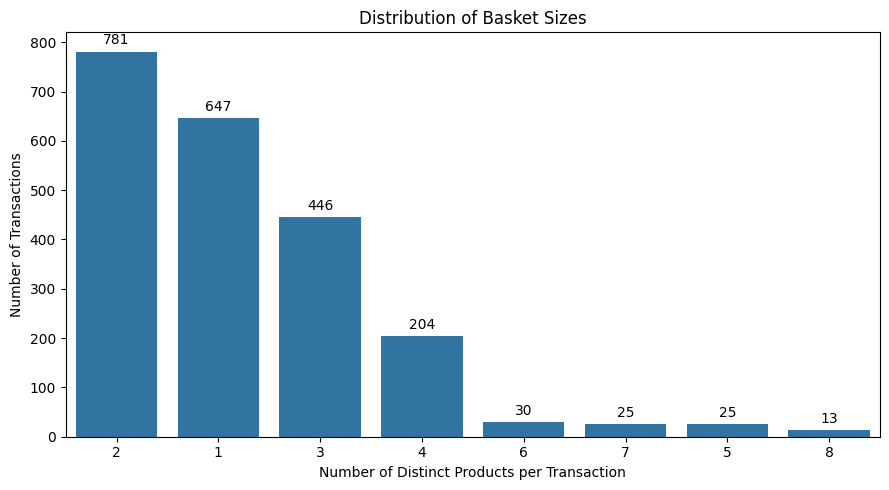

In [29]:
basket_size_counts = (
    items_per_order
    .value_counts()
    .sort_values(ascending= False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=basket_size_counts.index,
    y=basket_size_counts.values,
    order=basket_size_counts.index.tolist()
)

ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Distribution of Basket Sizes")
ax.set_xlabel("Number of Distinct Products per Transaction")
ax.set_ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [30]:
basket= pd.crosstab(
    df['Invoice_ID'],
    df['Product_Name']).astype(bool)
basket

Product_Name,Always Ultra Pack,Bathing Soap 6 Pack,Bournvita 500G,Cerelac 400G,Close-Up Toothpaste 140G,Coca-Cola 50Cl,Cornflakes 500G,Custard Powder 500G,Dangote Sugar 1Kg,Dettol Antiseptic 500Ml,...,Nivea Body Lotion 400Ml,Oral-B Toothpaste 140G,Pampers Jumbo Pack,Peak Milk Powder 400G,Power Oil 3L,Rechargeable Bulb,Serviette Pack,Sunlight Detergent 900G,Toilet Tissue 6 Rolls,Vaseline Lotion 400Ml
Invoice_ID,,,,,,,,,,,,,,,,,,,,,
INV-000001,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
INV-000002,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
INV-000003,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
INV-000004,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
INV-000005,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
INV-002167,False,False,False,False,False,False,False,True,False,False,...,False,True,False,False,False,False,False,False,True,False
INV-002168,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
INV-002169,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


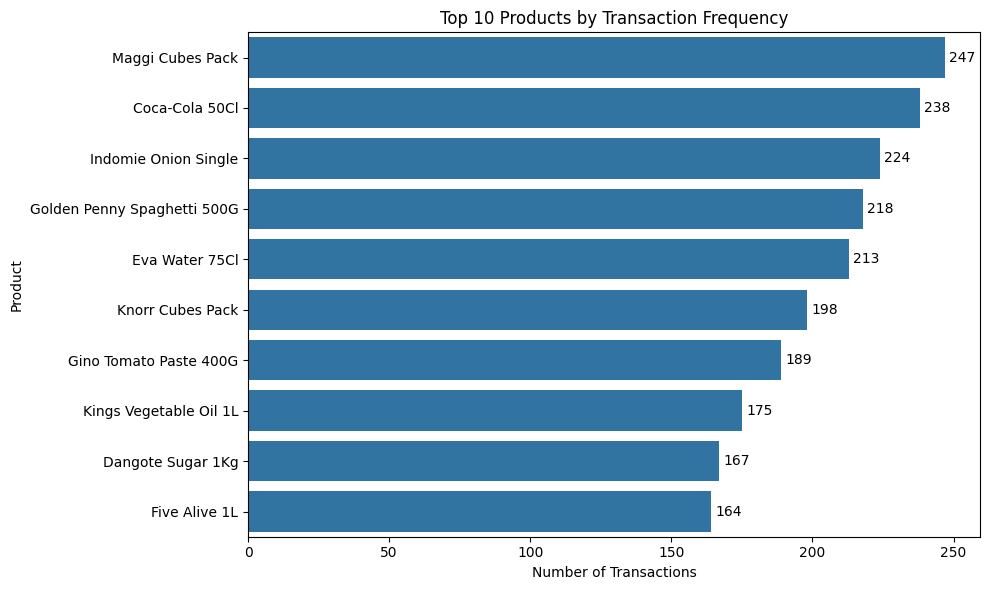

In [31]:
# Count the number of transactions containing each product.
# basket has one row per transaction and one column per product.
product_frequency = (
    basket.sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

product_frequency.columns = [
    "Product_Name",
    "Transaction_Count"
]

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=product_frequency,
    x="Transaction_Count",
    y="Product_Name"
)

ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Top 10 Products by Transaction Frequency")
ax.set_xlabel("Number of Transactions")
ax.set_ylabel("Product")

plt.tight_layout()
plt.show()

In [32]:
itemsets= apriori(basket,
                  min_support=0.01,
                  use_colnames=True,
                  n_jobs=-1)
itemsets

,support,itemsets
0,0.034546,frozenset({Always Ultra Pack})
1,0.050668,frozenset({Bathing Soap 6 Pack})
2,0.044680,frozenset({Bournvita 500G})
3,0.034086,frozenset({Cerelac 400G})
4,0.051589,frozenset({Close-Up Toothpaste 140G})
5,0.109627,frozenset({Coca-Cola 50Cl})
6,0.035007,frozenset({Cornflakes 500G})
7,0.040995,frozenset({Custard Powder 500G})
8,0.076923,frozenset({Dangote Sugar 1Kg})
9,0.038692,frozenset({Dettol Antiseptic 500Ml})


In [33]:
rules = association_rules(
    itemsets,
    metric="confidence",
    min_threshold=0
)

In [34]:
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

,antecedents,consequents,support,confidence,lift
0,frozenset({Eva Water 75Cl}),frozenset({Coca-Cola 50Cl}),0.011976,0.122066,1.113465
1,frozenset({Coca-Cola 50Cl}),frozenset({Eva Water 75Cl}),0.011976,0.109244,1.113465
2,frozenset({Coca-Cola 50Cl}),frozenset({Five Alive 1L}),0.010134,0.092437,1.223663
3,frozenset({Five Alive 1L}),frozenset({Coca-Cola 50Cl}),0.010134,0.134146,1.223663
4,frozenset({Golden Penny Spaghetti 500G}),frozenset({Coca-Cola 50Cl}),0.011515,0.114679,1.046084
5,frozenset({Coca-Cola 50Cl}),frozenset({Golden Penny Spaghetti 500G}),0.011515,0.105042,1.046084
6,frozenset({Indomie Chicken Carton}),frozenset({Coca-Cola 50Cl}),0.010594,0.186992,1.705712
7,frozenset({Coca-Cola 50Cl}),frozenset({Indomie Chicken Carton}),0.010594,0.096639,1.705712
8,frozenset({Indomie Onion Single}),frozenset({Coca-Cola 50Cl}),0.010134,0.098214,0.895896
9,frozenset({Coca-Cola 50Cl}),frozenset({Indomie Onion Single}),0.010134,0.092437,0.895896


In [35]:
rules.shape

(38, 14)

In [36]:
rules['transaction_count']= (
    rules['support']*total_transactions
).round().astype(int)

In [37]:
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift','transaction_count']]

,antecedents,consequents,support,confidence,lift,transaction_count
0,frozenset({Eva Water 75Cl}),frozenset({Coca-Cola 50Cl}),0.011976,0.122066,1.113465,26
1,frozenset({Coca-Cola 50Cl}),frozenset({Eva Water 75Cl}),0.011976,0.109244,1.113465,26
2,frozenset({Coca-Cola 50Cl}),frozenset({Five Alive 1L}),0.010134,0.092437,1.223663,22
3,frozenset({Five Alive 1L}),frozenset({Coca-Cola 50Cl}),0.010134,0.134146,1.223663,22
4,frozenset({Golden Penny Spaghetti 500G}),frozenset({Coca-Cola 50Cl}),0.011515,0.114679,1.046084,25
5,frozenset({Coca-Cola 50Cl}),frozenset({Golden Penny Spaghetti 500G}),0.011515,0.105042,1.046084,25
6,frozenset({Indomie Chicken Carton}),frozenset({Coca-Cola 50Cl}),0.010594,0.186992,1.705712,23
7,frozenset({Coca-Cola 50Cl}),frozenset({Indomie Chicken Carton}),0.010594,0.096639,1.705712,23
8,frozenset({Indomie Onion Single}),frozenset({Coca-Cola 50Cl}),0.010134,0.098214,0.895896,22
9,frozenset({Coca-Cola 50Cl}),frozenset({Indomie Onion Single}),0.010134,0.092437,0.895896,22


In [38]:
filtered_rules = rules[
    (rules['confidence'] >= 0.10) &
    (rules['lift'] > 1)
].sort_values(
    by=['lift', 'confidence'],
    ascending=False
).reset_index()

In [39]:
filtered_rules= filtered_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift','transaction_count']]
filtered_rules

,antecedents,consequents,support,confidence,lift,transaction_count
0,frozenset({Indomie Chicken Carton}),frozenset({Coca-Cola 50Cl}),0.010594,0.186992,1.705712,23
1,frozenset({Eva Water 75Cl}),frozenset({Indomie Onion Single}),0.016582,0.169014,1.638078,36
2,frozenset({Indomie Onion Single}),frozenset({Eva Water 75Cl}),0.016582,0.160714,1.638078,36
3,frozenset({Knorr Cubes Pack}),frozenset({Eva Water 75Cl}),0.012897,0.141414,1.441362,28
4,frozenset({Eva Water 75Cl}),frozenset({Knorr Cubes Pack}),0.012897,0.131455,1.441362,28
5,frozenset({Mama Gold Rice 5Kg}),frozenset({Maggi Cubes Pack}),0.011976,0.159509,1.402002,26
6,frozenset({Maggi Cubes Pack}),frozenset({Mama Gold Rice 5Kg}),0.011976,0.105263,1.402002,26
7,frozenset({Five Alive 1L}),frozenset({Golden Penny Spaghetti 500G}),0.010594,0.140244,1.396649,23
8,frozenset({Golden Penny Spaghetti 500G}),frozenset({Five Alive 1L}),0.010594,0.105505,1.396649,23
9,frozenset({Gino Tomato Paste 400G}),frozenset({Golden Penny Spaghetti 500G}),0.011976,0.137566,1.369982,26


In [40]:
filtered_rules['antecedents']= (filtered_rules['antecedents']
                                ).apply(lambda x: ', '.join(sorted(x)))
filtered_rules['consequents']= (filtered_rules['consequents']
                                ).apply(lambda x: ', '.join(sorted(x)))
filtered_rules['rules']= filtered_rules['antecedents'] + ' → ' + filtered_rules['consequents']
filtered_rules

,antecedents,consequents,support,confidence,lift,transaction_count,rules
0,Indomie Chicken Carton,Coca-Cola 50Cl,0.010594,0.186992,1.705712,23,Indomie Chicken Carton → Coca-Cola 50Cl
1,Eva Water 75Cl,Indomie Onion Single,0.016582,0.169014,1.638078,36,Eva Water 75Cl → Indomie Onion Single
2,Indomie Onion Single,Eva Water 75Cl,0.016582,0.160714,1.638078,36,Indomie Onion Single → Eva Water 75Cl
3,Knorr Cubes Pack,Eva Water 75Cl,0.012897,0.141414,1.441362,28,Knorr Cubes Pack → Eva Water 75Cl
4,Eva Water 75Cl,Knorr Cubes Pack,0.012897,0.131455,1.441362,28,Eva Water 75Cl → Knorr Cubes Pack
5,Mama Gold Rice 5Kg,Maggi Cubes Pack,0.011976,0.159509,1.402002,26,Mama Gold Rice 5Kg → Maggi Cubes Pack
6,Maggi Cubes Pack,Mama Gold Rice 5Kg,0.011976,0.105263,1.402002,26,Maggi Cubes Pack → Mama Gold Rice 5Kg
7,Five Alive 1L,Golden Penny Spaghetti 500G,0.010594,0.140244,1.396649,23,Five Alive 1L → Golden Penny Spaghetti 500G
8,Golden Penny Spaghetti 500G,Five Alive 1L,0.010594,0.105505,1.396649,23,Golden Penny Spaghetti 500G → Five Alive 1L
9,Gino Tomato Paste 400G,Golden Penny Spaghetti 500G,0.011976,0.137566,1.369982,26,Gino Tomato Paste 400G → Golden Penny Spaghett...


In [39]:
import seaborn as sns

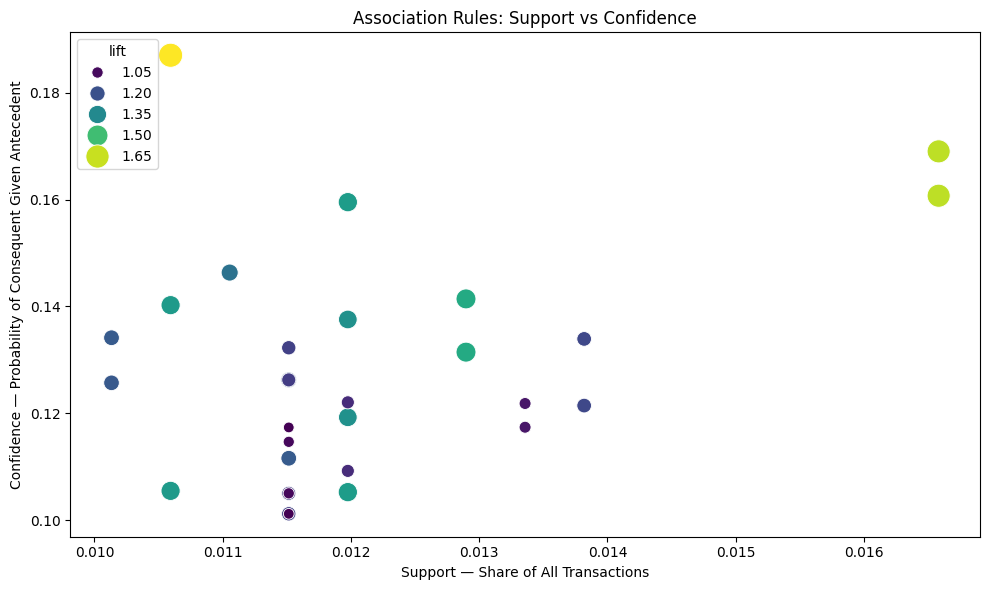

In [41]:
plt.figure(figsize=(10, 6))

ax = sns.scatterplot(
    data=filtered_rules,
    x="support",
    y="confidence",
    size="lift",
    hue="lift",
    sizes=(60, 300),
    palette="viridis",
    legend="brief"
)

ax.set_title("Association Rules: Support vs Confidence")
ax.set_xlabel("Support — Share of All Transactions")
ax.set_ylabel("Confidence — Probability of Consequent Given Antecedent")

plt.tight_layout()
plt.show()

In [42]:
top_rules= filtered_rules.nlargest(15,'lift').copy()

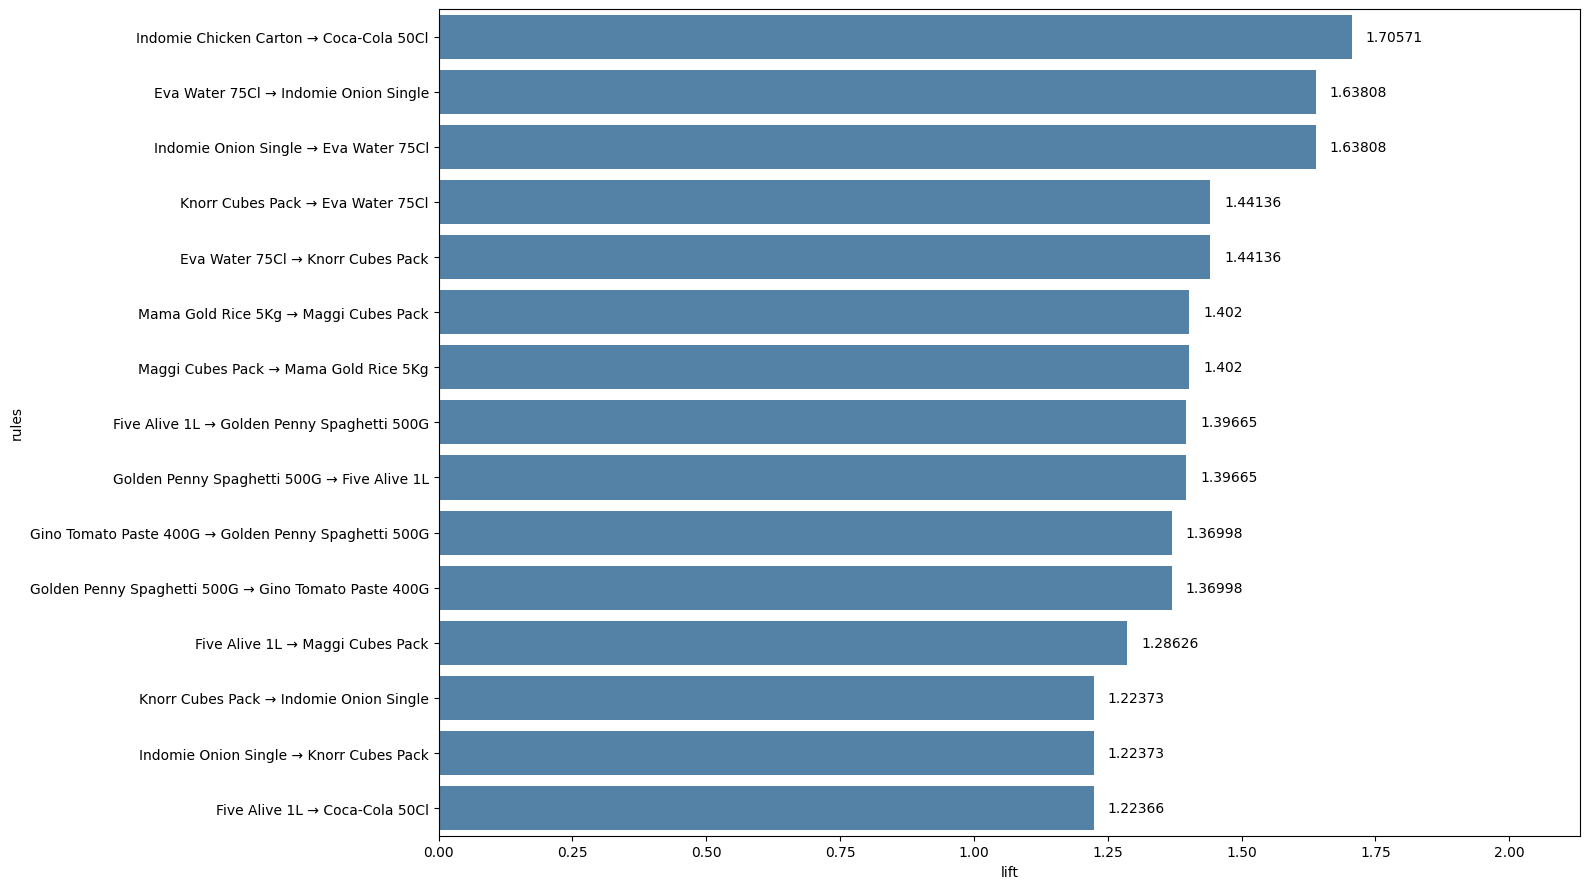

In [43]:
plt.figure(figsize=(16,9))
viz= sns.barplot(data=top_rules,x='lift',y='rules',color='steelblue')

for container in viz.containers:
    viz.bar_label(container,padding=10)
viz.set_xlim(0, top_rules['lift'].max() * 1.25)
plt.subplots_adjust(right=0.90, left=0.35)
plt.tight_layout()
plt.show()

<Figure size 1500x700 with 0 Axes>

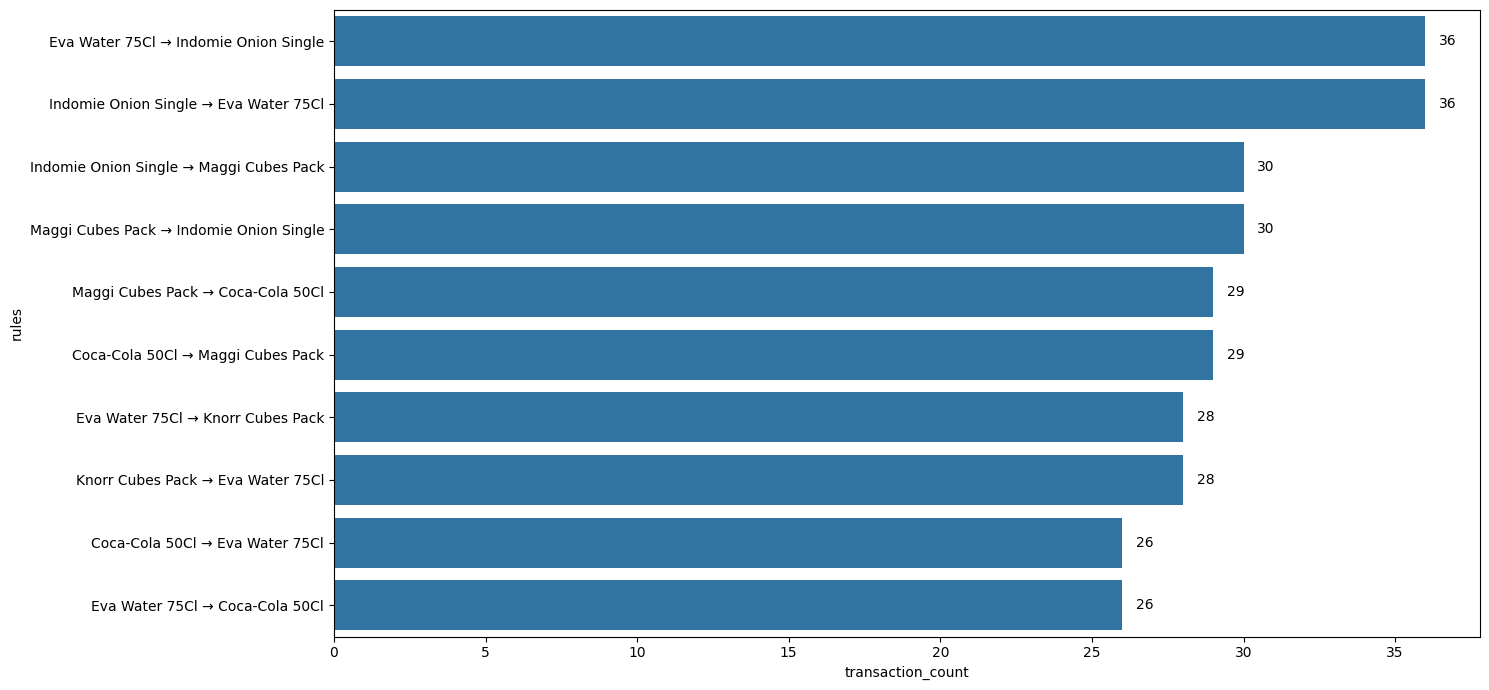

In [49]:

plt.figure(figsize=(15, 7))

sorted_rules = filtered_rules.sort_values(
    by='transaction_count',
    ascending=False
).head(10)
plt.figure(figsize=(15,7))
plot= sns.barplot(data=sorted_rules,x='transaction_count',y='rules')
for container in plot.containers:
    plot.bar_label(container,padding=10)
plt.tight_layout()
plt.show()

## Business Recommendations

Based on the association rules generated from the transaction data, the following actions are recommended:

### 1. Introduce Targeted Product Bundling

The analysis identified associations between products such as Indomie Chicken Carton and Coca-Cola 50cl. This rule had a support of approximately 1.06%, a confidence of 18.70%, and a lift of 1.71.

The retailer could test a promotional bundle featuring these products to determine whether offering them together encourages additional purchases. The bundle should be tested as a pilot rather than implemented permanently based on the association alone.

### 2. Test Cross-Merchandising Strategies

Products that frequently occur together in transactions could be displayed near one another, where practical. For example, the association between Eva Water 75cl and Indomie Onion Single could inform a trial involving product placement or complementary promotions.

The retailer should compare sales performance before and during the trial to determine whether the arrangement improves product sales or increases the number of items purchased per transaction.

### 3. Use Association Rules to Support Promotional Planning

The retailer can use the discovered associations to identify potential combinations for discounts, checkout recommendations, or targeted promotions. However, products should not be bundled solely because they have a high lift value. Their selling prices, profit margins, stock availability, and promotional costs should also be considered.

### 4. Monitor the Performance of Recommended Product Combinations

Any recommended bundles or cross-selling initiatives should be evaluated using measurable business indicators, including:
- Bundle take-up or add-on purchase rate.
- Average transaction value.
- Units sold for the associated products.
- Gross profit and profit margin.
- Inventory availability and stock movement.

Where possible, the retailer should compare transactions exposed to a promotion with a suitable control group that was not exposed to it.

### 5. Review and Update the Association Rules Periodically

Customer purchasing patterns may change over time. The retailer should periodically rerun the analysis on more recent transaction data to identify changes in product associations and determine whether previously useful combinations remain relevant.

## Limitations of the Analysis

### 1. Associations Do Not Establish Causation

The analysis identifies products that tend to occur together in transactions. It does not establish that purchasing one product causes a customer to purchase another. Additional testing would be required to determine whether a bundle or promotional campaign actually changes purchasing behaviour.

### 2. Some Associations Have Limited Transaction Coverage

The minimum support threshold was set to 0.01, meaning that itemsets had to appear in at least approximately 1% of transactions to qualify for the frequent-itemset stage. Some resulting associations therefore represent a relatively small number of transactions.

For example, the Indomie Chicken Carton and Coca-Cola 50cl association had support of approximately 1.06%, equivalent to about 23 transactions in the analysed dataset. Such findings should be validated on additional transaction data before being used to make major business decisions.

### 3. Results Depend on the Selected Thresholds

The Apriori analysis used a minimum support of 1%, while the displayed association rules were filtered using confidence of at least 10% and lift greater than 1. Different thresholds could produce a different number and composition of rules. The selected thresholds represent analytical choices and should be reviewed in relation to the retailer's business objectives.

### 4. Profitability Was Not Directly Evaluated

The association rules describe purchasing patterns, but the analysis did not establish whether the associated product combinations are profitable to promote. Product costs, margins, discount expenses, and potential cannibalisation of other sales would need to be considered before implementing promotional recommendations.

### 5. Product-Name Consistency Can Affect the Results

Product labels must be standardised before basket construction. Differences in spelling, capitalisation, or naming conventions may cause the same product to be treated as separate items, potentially affecting item frequencies and association rules. Product names should therefore be cleaned and validated before the final analysis is published.

### 6. The Findings May Not Generalise to Other Periods or Retailers

The results reflect the transactions included in this dataset. Purchasing behaviour may vary by season, location, customer group, product availability, or promotional activity. The identified associations should not automatically be assumed to apply to other retailers or future periods.

## Conclusion

This project applied market basket analysis using the Apriori algorithm to identify product combinations that frequently appeared together in transaction data. Association rules were evaluated using support, confidence, and lift to identify potentially useful cross-selling and product-bundling opportunities.

The findings provide a starting point for data-driven merchandising and promotional decisions. However, the associations should be validated through further analysis and controlled business trials, particularly because some rules are supported by relatively few transactions and the analysis does not directly measure promotional profitability.

Overall, market basket analysis can help retailers better understand purchasing patterns and develop testable strategies for improving product discovery and sales performance.